                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1460.000000  1460.000000  1201.000000    1460.000000  1460.000000   
mean    730.500000    56.897260    70.049958   10516.828082     6.099315   
std     421.610009    42.300571    24.284752    9981.264932     1.382997   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     365.750000    20.000000    59.000000    7553.500000     5.000000   
50%     730.500000    50.000000    69.000000    9478.500000     6.000000   
75%    1095.250000    70.000000    80.000000   11601.500000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1460.000000  1460.000000   1460.000000  1452.000000  1460.000000  ...   
mean      5.575342  1971.267808   1984.865753   103.685262   443.639726  ...   
std       1.112799    30.202904     20.645407   181.066207   456.098091  ..

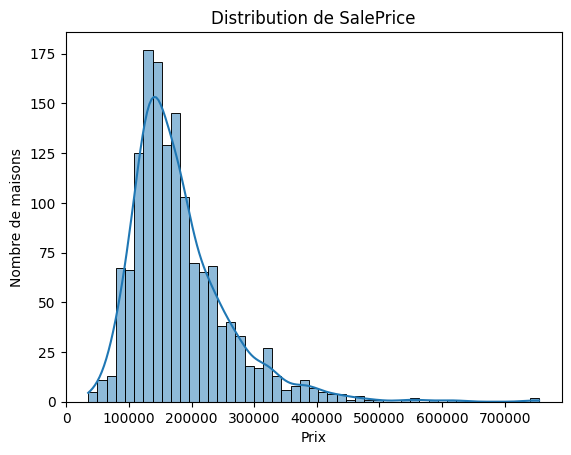

Colonnes numériques : 36
Colonnes catégorielles : 43
Taille X_train_processed : (1168, 285)
Taille X_test_processed : (292, 285)
=== Régression Linéaire ===
MSE : 868709192.8794286
R2  : 0.8867441658393297
=== Random Forest ===
MSE : 808384987.248317
R2  : 0.8946087864567146
=== XGBoost ===
MSE : 646938304.0
R2  : 0.9156569838523865
     Réel      LR_Prédit  RF_Prédit     XGB_Prédit
0  154500  157609.214868  141606.00  141238.531250
1  325000  348503.304341  326323.31  326317.375000
2  115000   86473.723502  116127.75  109140.320312
3  159000  174161.642832  154427.20  168770.531250
4  315500  316991.413882  316095.72  303839.125000
5   75500   66791.517156   85738.50   80989.375000
6  311500  236155.120502  208216.48  217776.171875
7  146000  146009.088581  150584.50  148674.812500
8   84500   57574.418433   84343.49   80501.382812
9  135500  154052.468857  129272.37  130508.484375


In [1]:
# ------------------------------
# 1️⃣ Importer les librairies
# ------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

# ------------------------------
# 2️⃣ Charger les données
# ------------------------------
data = pd.read_csv("../data/train.csv")

# Aperçu rapide
print(data.describe())
print("Valeurs manquantes par colonne :")
print(data.isnull().sum().sort_values(ascending=False).head(20))

# Distribution du prix des maisons
sns.histplot(data['SalePrice'], kde=True)
plt.title("Distribution de SalePrice")
plt.xlabel("Prix")
plt.ylabel("Nombre de maisons")
plt.show()

# ------------------------------
# 3️⃣ Séparer X et y
# ------------------------------
X = data.drop(['Id', 'SalePrice'], axis=1)
y = data['SalePrice']

# Colonnes numériques et catégorielles
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'string']).columns

print("Colonnes numériques :", len(num_cols))
print("Colonnes catégorielles :", len(cat_cols))

# ------------------------------
# 4️⃣ Définir le préprocessing
# ------------------------------
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

# ------------------------------
# 5️⃣ Split train/test
# ------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ------------------------------
# 6️⃣ Appliquer le préprocessing
# ------------------------------
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Taille X_train_processed :", X_train_processed.shape)
print("Taille X_test_processed :", X_test_processed.shape)

# ------------------------------
# 7️⃣ Régression Linéaire
# ------------------------------
lr_model = LinearRegression()
lr_model.fit(X_train_processed, y_train)
y_pred_lr = lr_model.predict(X_test_processed)

print("=== Régression Linéaire ===")
print("MSE :", mean_squared_error(y_test, y_pred_lr))
print("R2  :", r2_score(y_test, y_pred_lr))

# ------------------------------
# 8️⃣ Random Forest
# ------------------------------
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_processed, y_train)
y_pred_rf = rf_model.predict(X_test_processed)

print("=== Random Forest ===")
print("MSE :", mean_squared_error(y_test, y_pred_rf))
print("R2  :", r2_score(y_test, y_pred_rf))

# ------------------------------
# 9️⃣ XGBoost
# ------------------------------
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_processed, y_train)
y_pred_xgb = xgb_model.predict(X_test_processed)

print("=== XGBoost ===")
print("MSE :", mean_squared_error(y_test, y_pred_xgb))
print("R2  :", r2_score(y_test, y_pred_xgb))

# ------------------------------
# 10️⃣ Comparer quelques prédictions
# ------------------------------
comparison_df = pd.DataFrame({
    "Réel": y_test,
    "LR_Prédit": y_pred_lr,
    "RF_Prédit": y_pred_rf,
    "XGB_Prédit": y_pred_xgb
}).reset_index(drop=True)

print(comparison_df.head(10))


In [3]:
# Supposons que ton DataFrame final nettoyé et encodé s'appelle df
data.to_csv("../data/train_clean.csv", index=False)



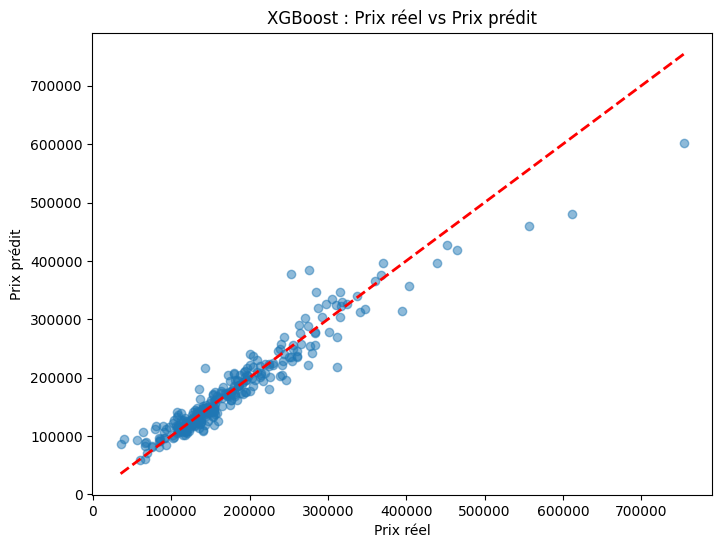

In [8]:
#Analyse des erreurs
import matplotlib.pyplot as plt


plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_xgb, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Prix réel")
plt.ylabel("Prix prédit")
plt.title("XGBoost : Prix réel vs Prix prédit")
plt.show()



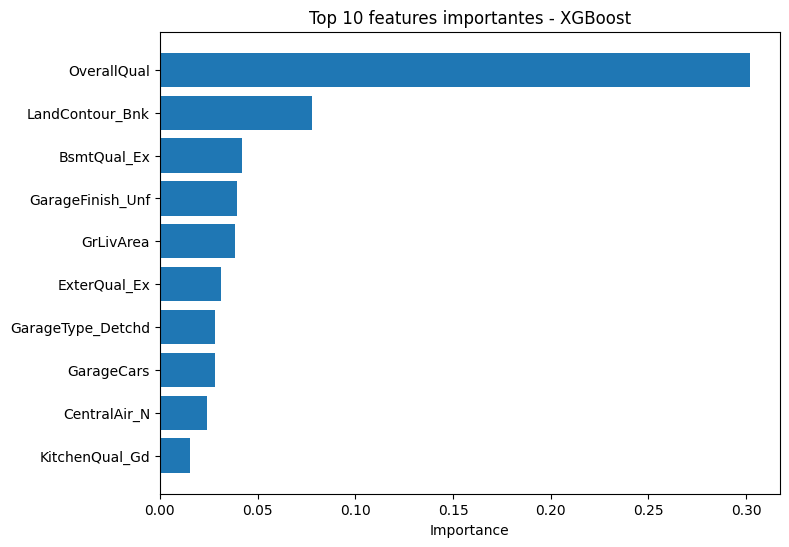

In [9]:
#Feature Importance
# Obtenir les noms des colonnes après prétraitement
import numpy as np

# Pour les colonnes numériques
num_features = num_cols

# Pour les colonnes catégorielles encodées
cat_features = preprocessor.named_transformers_['cat']['encoder'].get_feature_names_out(cat_cols)

# Combiner les deux
all_features = np.concatenate([num_features, cat_features])

# Top 10 features importantes
importances = xgb_model.feature_importances_
indices = importances.argsort()[-10:]

# Graphique
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), all_features[indices])
plt.xlabel("Importance")
plt.title("Top 10 features importantes - XGBoost")
plt.show()



In [11]:
import pandas as pd

# Comparer les 3 modèles avec les nouveaux scores
comparison = pd.DataFrame({
    "Modèle": ["Régression Linéaire", "Random Forest", "XGBoost"],
    "MSE": [868709192.8794286, 808384987.248317, 646938304.0],
    "R2": [0.8867441658393297, 0.8946087864567146, 0.9156569838523865]
})

print(comparison)


                Modèle           MSE        R2
0  Régression Linéaire  8.687092e+08  0.886744
1        Random Forest  8.083850e+08  0.894609
2              XGBoost  6.469383e+08  0.915657


In [14]:
X_train.columns


Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
       'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
       'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
       'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle',
       'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
       'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd',
       'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt',
       'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',
       'PavedDrive', 'Wo